<a href="https://colab.research.google.com/github/hafizzx/python-projects/blob/main/logestic_regression_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
from sklearn.datasets import make_classification
import numpy as np
X, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

In [27]:
import matplotlib.pyplot as plt

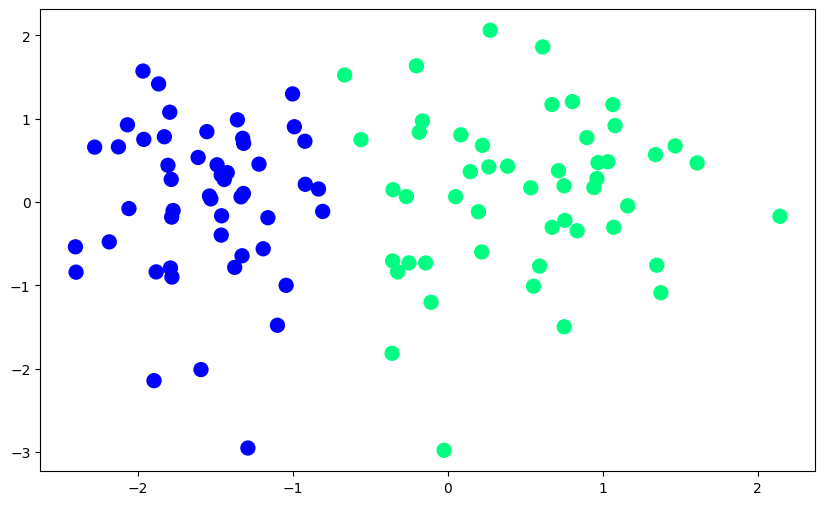

In [28]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [31]:
def perceptron(X,y):

    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]

    return weights[0],weights[1:]

In [30]:
def step(z):
    return 1 if z>0 else 0

In [32]:
intercept_,coef_ = perceptron(X,y)

In [33]:
print(coef_)
print(intercept_)

[1.38295756 0.22250049]
0.9


In [34]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [35]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

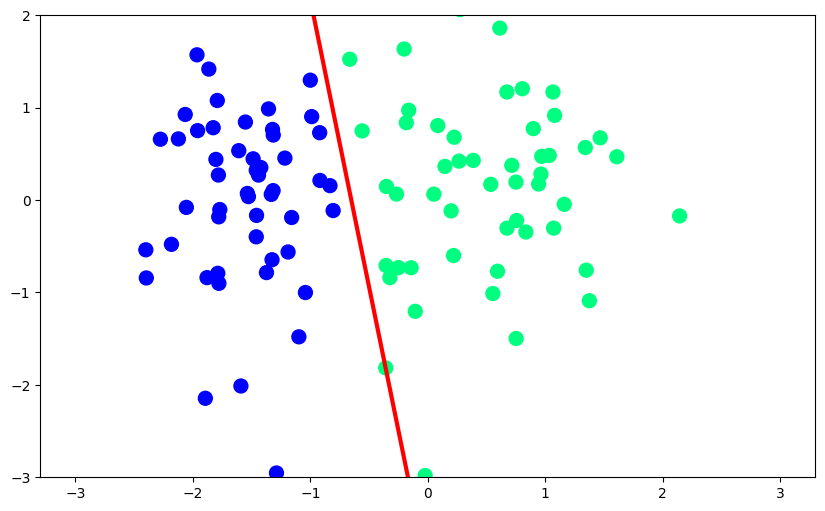

In [36]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [37]:
def perceptron(X,y):

    m = []
    b = []

    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(200):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]

        m.append(-(weights[1]/weights[2]))
        b.append(-(weights[0]/weights[2]))

    return m,b

In [38]:
m,b = perceptron(X,y)

In [47]:
print("Length of m:", len(m))
print("Length of b:", len(b))

Length of m: 200
Length of b: 200


In [49]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# 200 iterations or available values
n = min(200, len(m), len(b))

x_i = np.arange(-3, 3, 0.1)

# Original data points
df = pd.DataFrame({
    "Feature 1": X[:, 0],
    "Feature 2": X[:, 1],
    "Class": y.astype(str)
})

# Scatter plot
fig = px.scatter(
    df,
    x="Feature 1",
    y="Feature 2",
    color="Class",
    title="Decision Boundary Animation (200 Iterations)",
    range_x=[-3, 3],
    range_y=[-3, 3],
    color_discrete_sequence=["blue", "green"]
)

# Initial decision boundary
fig.add_trace(
    go.Scatter(
        x=x_i,
        y=x_i * m[0] + b[0],
        mode="lines",
        name="Decision Boundary",
        line=dict(color="red", width=3)
    )
)

# Animation frames
fig.frames = [
    go.Frame(
        name=str(i + 1),
        data=[
            go.Scatter(
                x=x_i,
                y=x_i * m[i] + b[i],
                mode="lines",
                line=dict(color="red", width=3)
            )
        ],
        traces=[1]
    )
    for i in range(n)
]

# Play button and iteration slider
fig.update_layout(
    xaxis_title="Feature 1",
    yaxis_title="Feature 2",
    updatemenus=[{
        "type": "buttons",
        "buttons": [{
            "label": "▶ Play",
            "method": "animate",
            "args": [None, {
                "frame": {"duration": 100, "redraw": True},
                "transition": {"duration": 0},
                "fromcurrent": True
            }]
        }]
    }],
    sliders=[{
        "currentvalue": {"prefix": "Iteration: "},
        "steps": [
            {
                "label": str(i + 1),
                "method": "animate",
                "args": [[str(i + 1)], {
                    "mode": "immediate",
                    "frame": {"duration": 0, "redraw": True},
                    "transition": {"duration": 0}
                }]
            }
            for i in range(n)
        ]
    }]
)

fig.show()

In [50]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression()
lor.fit(X,y)

LogisticRegression()

In [51]:
m = -(lor.coef_[0][0]/lor.coef_[0][1])
b = -(lor.intercept_/lor.coef_[0][1])

In [52]:
x_input1 = np.linspace(-3,3,100)
y_input1 = m*x_input + b

In [55]:
import plotly.express as px

fig = px.scatter(x=X[:,0], y=X[:,1], color=y.astype(str))
fig.add_scatter(x=x_input, y=y_input, line=dict(color="red", width=3))
fig.add_scatter(x=x_input1, y=y_input1, line=dict(color="black", width=3))
fig.update_layout(width=1000, height=600, yaxis_range=[-3, 2])
fig.show()

In [58]:
def perceptron(X,y):

    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = sigmoid(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]

    return weights[0],weights[1:]

In [57]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

In [59]:
intercept_,coef_ = perceptron(X,y)

In [60]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [61]:
x_input2 = np.linspace(-3,3,100)
y_input2 = m*x_input + b

In [62]:
import plotly.express as px

fig = px.scatter(x=X[:, 0], y=X[:, 1], color=y.astype(str),
                 color_discrete_sequence=["blue", "green"])

fig.add_scatter(x=x_input, y=y_input, mode="lines", line=dict(color="red", width=3))
fig.add_scatter(x=x_input1, y=y_input1, mode="lines", line=dict(color="black", width=3))
fig.add_scatter(x=x_input2, y=y_input2, mode="lines", line=dict(color="brown", width=3))

fig.update_layout(width=1000, height=600, yaxis_range=[-3, 2])
fig.show()

In [63]:
print(lor.coef_)
print(lor.intercept_)

[[3.50144121 0.02773483]]
[2.25106636]


In [64]:
m1 = -(lor.coef_[0][0]/lor.coef_[0][1])
b1 = -(lor.intercept_/lor.coef_[0][1])

In [65]:
x_input = np.linspace(-3,3,100)
y_input = m1*x_input + b1

In [67]:
def gd(X,y):

    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.5

    for i in range(5000):
        y_hat = sigmoid(np.dot(X,weights))
        weights = weights + lr*(np.dot((y-y_hat),X)/X.shape[0])

    return weights[1:],weights[0]

In [66]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

In [68]:
coef_,intercept_ = gd(X,y)

In [70]:
print(coef_)
print(intercept_)

[11.9130685   0.80686829]
7.890931726180508


In [69]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [71]:
print(m)

-14.764576455210598


In [72]:
print(b)

-9.77970241192825
